# Handwritten Digit Recognition with a CNN (MNIST)

A Convolutional Neural Network built with TensorFlow/Keras that recognizes handwritten digits (0-9).
The notebook trains the model, evaluates it, and analyzes its mistakes with a confusion matrix.

**How to run on Google Colab:** `Runtime` → `Run all`.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

## 2. Load and prepare the data

MNIST contains 60,000 training images and 10,000 test images (28x28 pixels, grayscale).
Pixel values are scaled from 0-255 to 0-1, and a channel dimension is added: `(28, 28)` → `(28, 28, 1)`.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


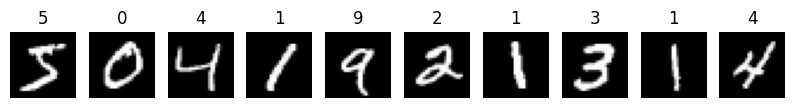

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print("Train shape:", x_train.shape)
print("Test shape:", x_test.shape)

# A few examples
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

## 3. Build the CNN

Two convolution + pooling blocks extract visual features (strokes, curves), dropout reduces overfitting, and a final softmax layer outputs one probability per digit.

In [3]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

10% of the training data is used for validation.

In [4]:
history = model.fit(
    x_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.1,
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 100ms/step - accuracy: 0.8877 - loss: 0.3679 - val_accuracy: 0.9765 - val_loss: 0.0812
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9666 - loss: 0.1094 - val_accuracy: 0.9837 - val_loss: 0.0581
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9741 - loss: 0.0846 - val_accuracy: 0.9877 - val_loss: 0.0452
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - accuracy: 0.9786 - loss: 0.0690 - val_accuracy: 0.9893 - val_loss: 0.0409
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9809 - loss: 0.0610 - val_accuracy: 0.9903 - val_loss: 0.0393
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9822 - loss: 0.0572 - val_accuracy: 0.9910 - val_loss: 0.0363
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9836 - loss: 0.0518 - val_accuracy: 0.9908 - val_loss: 0.0348
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9851 - loss: 0.0478

## 5. Training curves

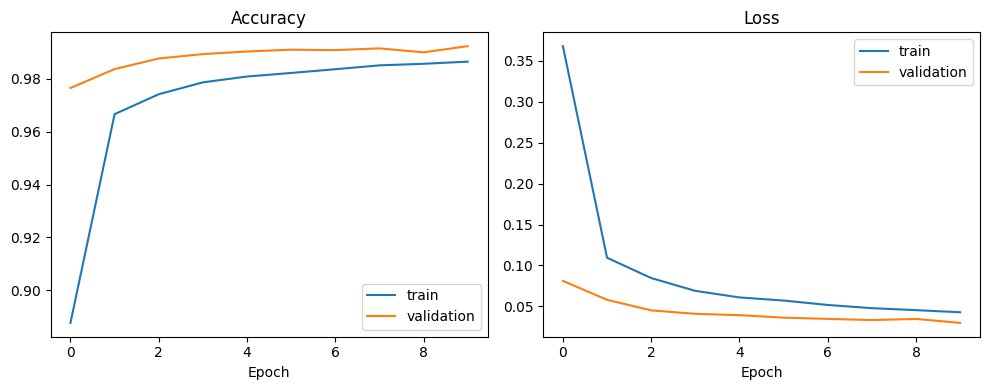

In [5]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## 6. Evaluate on the test set

In [6]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Test accuracy: 99.11%


## 7. Confusion matrix

Rows are the true digits, columns are the predicted digits. Everything outside the diagonal is a mistake.

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


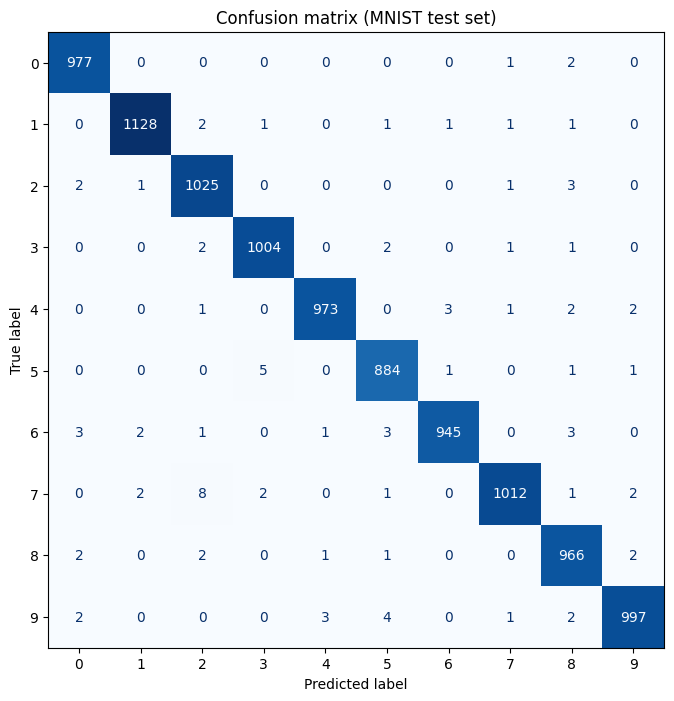

              precision    recall  f1-score   support

           0     0.9909    0.9969    0.9939       980
           1     0.9956    0.9938    0.9947      1135
           2     0.9846    0.9932    0.9889      1032
           3     0.9921    0.9941    0.9931      1010
           4     0.9949    0.9908    0.9929       982
           5     0.9866    0.9910    0.9888       892
           6     0.9947    0.9864    0.9906       958
           7     0.9941    0.9844    0.9892      1028
           8     0.9837    0.9918    0.9877       974
           9     0.9930    0.9881    0.9906      1009

    accuracy                         0.9911     10000
   macro avg     0.9910    0.9911    0.9910     10000
weighted avg     0.9911    0.9911    0.9911     10000



In [7]:
y_pred = np.argmax(model.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (MNIST test set)")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, y_pred, digits=4))

## 8. Which digits does the model confuse the most?

Most frequent mistakes:
  True 7 predicted as 2: 8 times
  True 5 predicted as 3: 5 times
  True 9 predicted as 5: 4 times
  True 9 predicted as 4: 3 times
  True 6 predicted as 8: 3 times


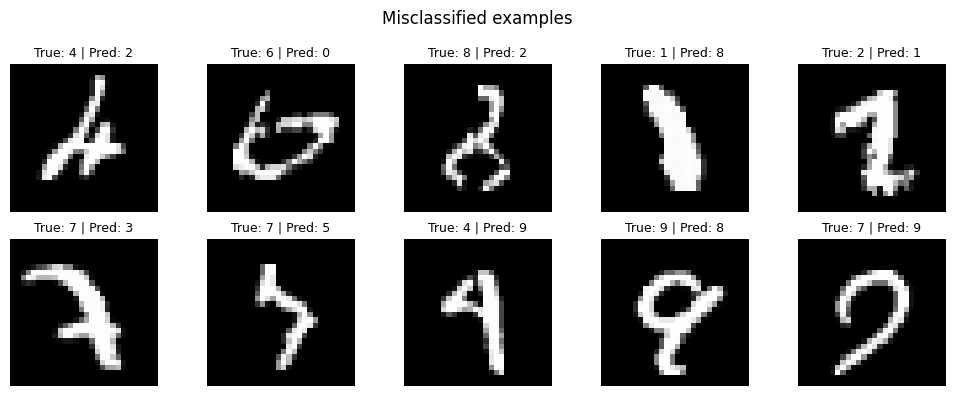

In [8]:
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

pairs = []
for true_digit in range(10):
    for pred_digit in range(10):
        if cm_errors[true_digit, pred_digit] > 0:
            pairs.append((cm_errors[true_digit, pred_digit], true_digit, pred_digit))
pairs.sort(reverse=True)

print("Most frequent mistakes:")
for count, true_digit, pred_digit in pairs[:5]:
    print(f"  True {true_digit} predicted as {pred_digit}: {count} times")

# Misclassified examples
wrong = np.where(y_pred != y_test)[0]
plt.figure(figsize=(10, 4))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Misclassified examples")
plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=150)
plt.show()

## 9. Save the model and download the results

On Google Colab this downloads a zip with the model and the three images.

In [9]:
model.save("mnist_cnn_model.keras")

import zipfile
files_to_zip = [
    "mnist_cnn_model.keras",
    "training_curves.png",
    "confusion_matrix.png",
    "misclassified_examples.png",
]
with zipfile.ZipFile("results.zip", "w") as z:
    for f in files_to_zip:
        z.write(f)

try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("Saved results.zip in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Interactive demo: draw a digit

Draw a digit with the mouse (or your finger) and the trained CNN predicts it. The drawing is cropped, resized and centered like MNIST images before being sent to the model. Run this cell after training.

In [10]:
# Interactive demo for Google Colab: draw a digit and let the trained CNN predict it.
# Run this cell AFTER the model has been trained (the variable `model` must exist).

import base64
import io

import numpy as np
from PIL import Image
from IPython.display import display, HTML, JSON
from google.colab import output


def preprocess(img):
    """White digit on black (mode 'L') -> CNN input of shape (1, 28, 28, 1).

    MNIST digits are centered in a 20x20 box inside a 28x28 image,
    so the drawing is cropped, resized and centered the same way.
    """
    arr = np.array(img)
    ys, xs = np.where(arr > 20)
    if len(xs) == 0:
        return None
    img = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
    w, h = img.size
    scale = 20.0 / max(w, h)
    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))
    img = img.resize((new_w, new_h), Image.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(img, ((28 - new_w) // 2, (28 - new_h) // 2))
    arr = np.array(canvas).astype("float32") / 255.0
    return arr.reshape(1, 28, 28, 1)


def predict_digit(data_url):
    """Called from the browser with the drawing as a PNG data URL."""
    b64 = data_url.split(",")[1]
    img = Image.open(io.BytesIO(base64.b64decode(b64))).convert("L")
    x = preprocess(img)
    if x is None:
        return JSON({"text": "Draw a digit first", "details": ""})
    probs = model.predict(x, verbose=0)[0]
    top3 = np.argsort(probs)[::-1][:3]
    return JSON({
        "text": f"Prediction: {top3[0]} ({probs[top3[0]] * 100:.1f}%)",
        "details": "Top 3: " + ", ".join(f"{d} ({probs[d] * 100:.1f}%)" for d in top3),
    })


output.register_callback("notebook.predict_digit", predict_digit)

display(HTML("""
<div style="font-family: Arial, sans-serif">
  <p>Draw a digit (0-9) with the mouse or your finger:</p>
  <canvas id="pad" width="280" height="280"
          style="background:black; border:2px solid #888; cursor:crosshair; touch-action:none"></canvas>
  <br>
  <button id="btn-predict" style="font-size:16px; padding:6px 16px">Predict</button>
  <button id="btn-clear" style="font-size:16px; padding:6px 16px">Clear</button>
  <h2 id="result">Prediction: -</h2>
  <div id="details"></div>
</div>
<script>
(function () {
  const c = document.getElementById('pad');
  const ctx = c.getContext('2d');
  ctx.fillStyle = 'black';
  ctx.fillRect(0, 0, c.width, c.height);
  ctx.strokeStyle = 'white';
  ctx.lineWidth = 20;
  ctx.lineCap = 'round';
  ctx.lineJoin = 'round';
  let drawing = false;

  function pos(e) {
    const r = c.getBoundingClientRect();
    const t = e.touches ? e.touches[0] : e;
    return [(t.clientX - r.left) * c.width / r.width,
            (t.clientY - r.top) * c.height / r.height];
  }
  function start(e) {
    drawing = true;
    const p = pos(e);
    ctx.beginPath();
    ctx.moveTo(p[0], p[1]);
    ctx.lineTo(p[0] + 0.1, p[1] + 0.1);
    ctx.stroke();
    e.preventDefault();
  }
  function move(e) {
    if (!drawing) return;
    const p = pos(e);
    ctx.lineTo(p[0], p[1]);
    ctx.stroke();
    e.preventDefault();
  }
  function stop() { drawing = false; }

  c.addEventListener('mousedown', start);
  c.addEventListener('mousemove', move);
  window.addEventListener('mouseup', stop);
  c.addEventListener('touchstart', start);
  c.addEventListener('touchmove', move);
  c.addEventListener('touchend', stop);

  document.getElementById('btn-clear').onclick = function () {
    ctx.fillStyle = 'black';
    ctx.fillRect(0, 0, c.width, c.height);
    document.getElementById('result').innerText = 'Prediction: -';
    document.getElementById('details').innerText = '';
  };

  document.getElementById('btn-predict').onclick = async function () {
    const res = await google.colab.kernel.invokeFunction(
      'notebook.predict_digit', [c.toDataURL('image/png')], {});
    const out = res.data['application/json'];
    document.getElementById('result').innerText = out.text;
    document.getElementById('details').innerText = out.details;
  };
})();
</script>
"""))
